<a href="https://colab.research.google.com/github/haasinisalihundam-netizen/ML-2520090170/blob/Practicals/ML_Practical_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving placement_predict_50k Dataset (1).csv to placement_predict_50k Dataset (1) (1).csv


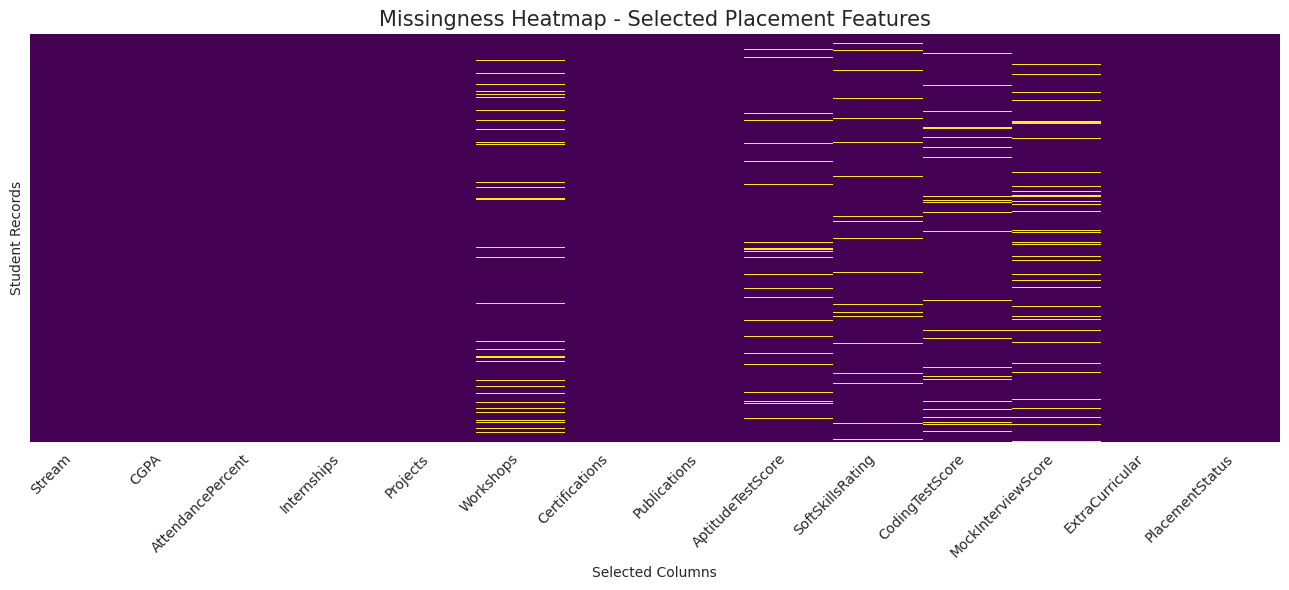

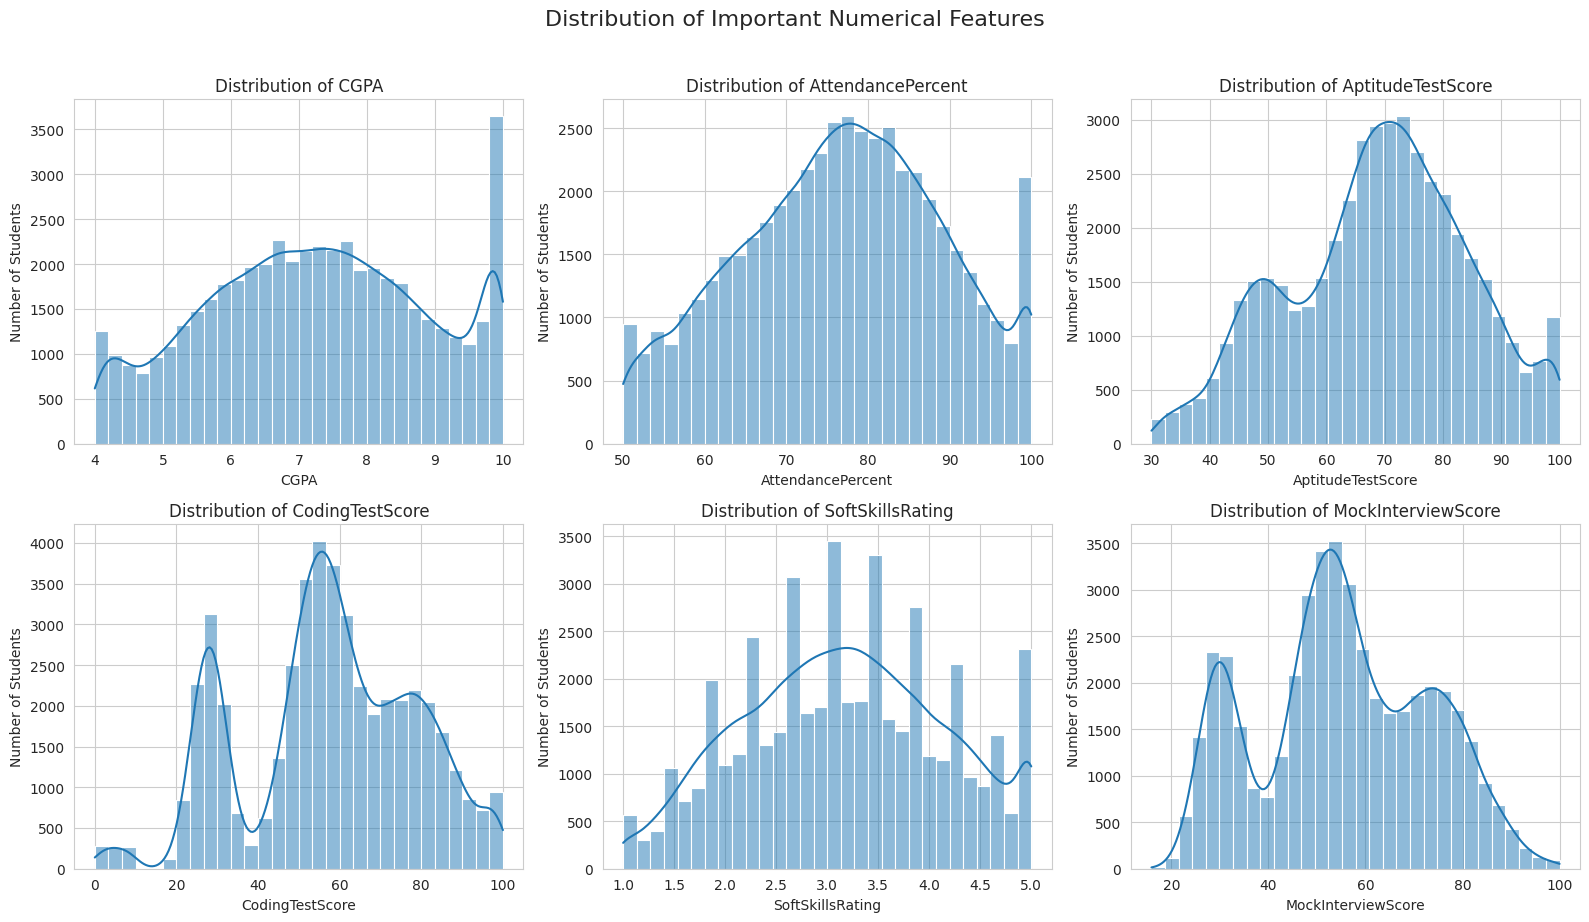

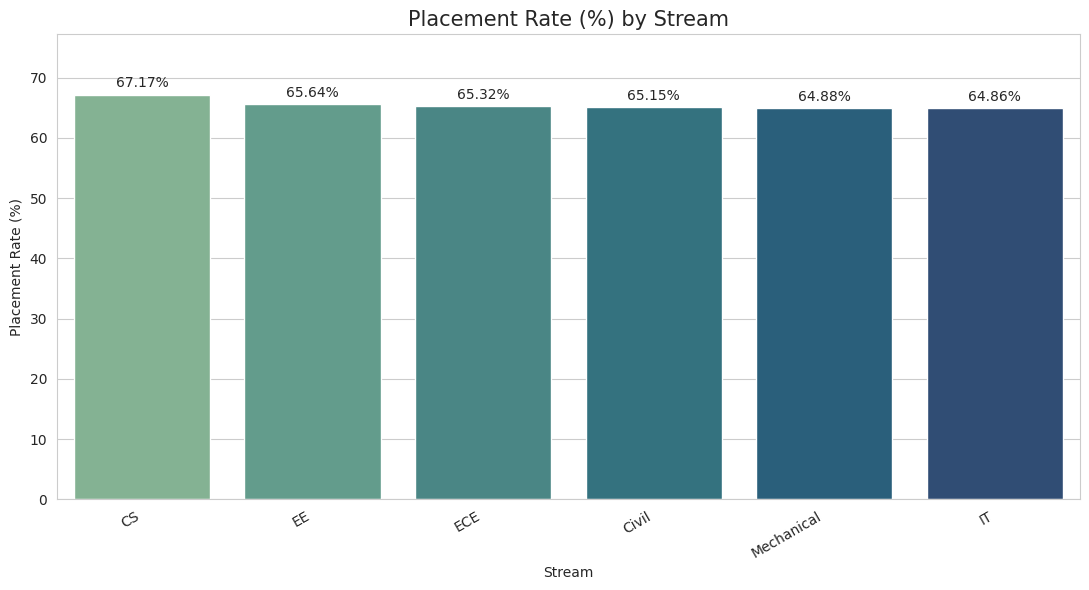

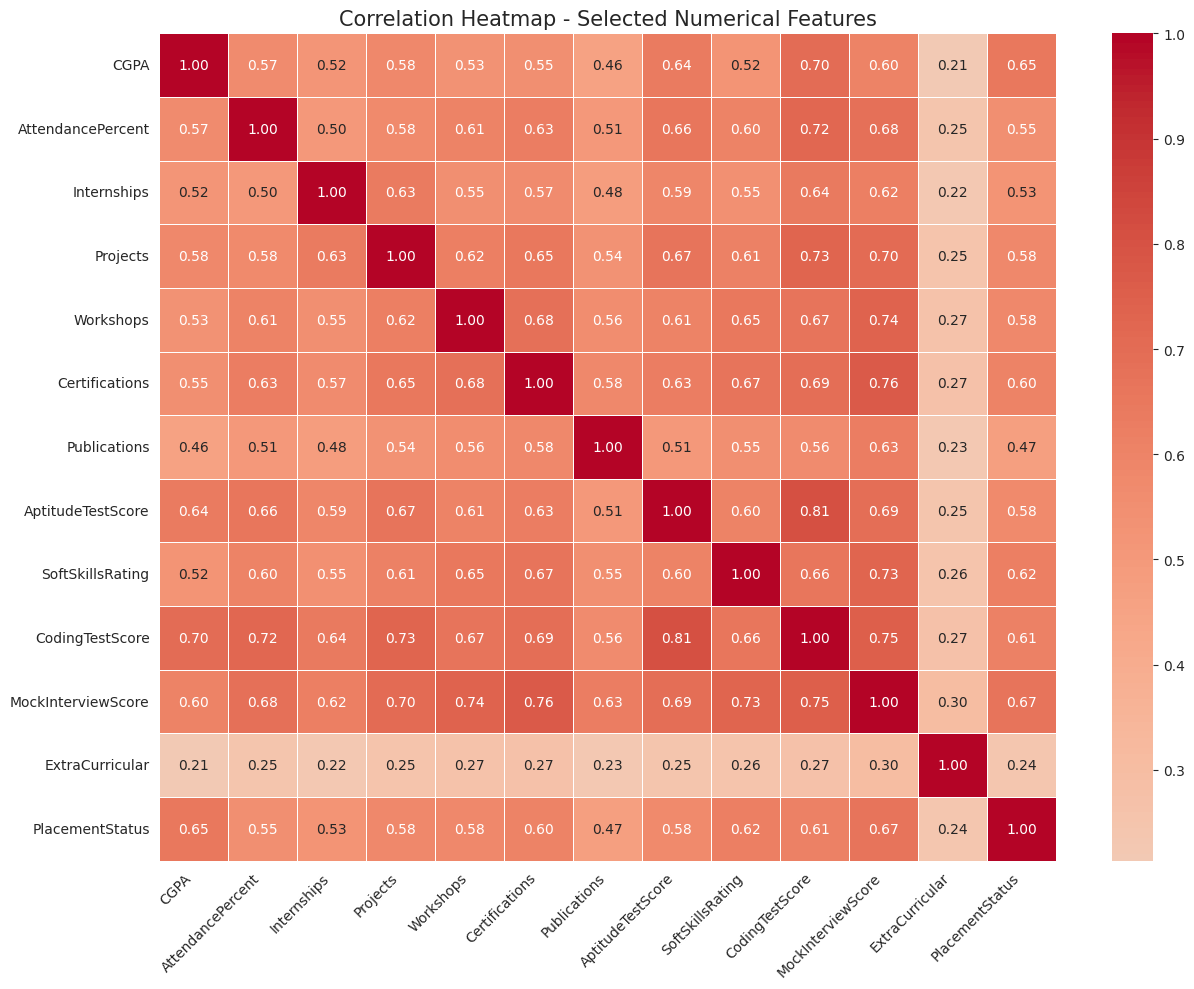

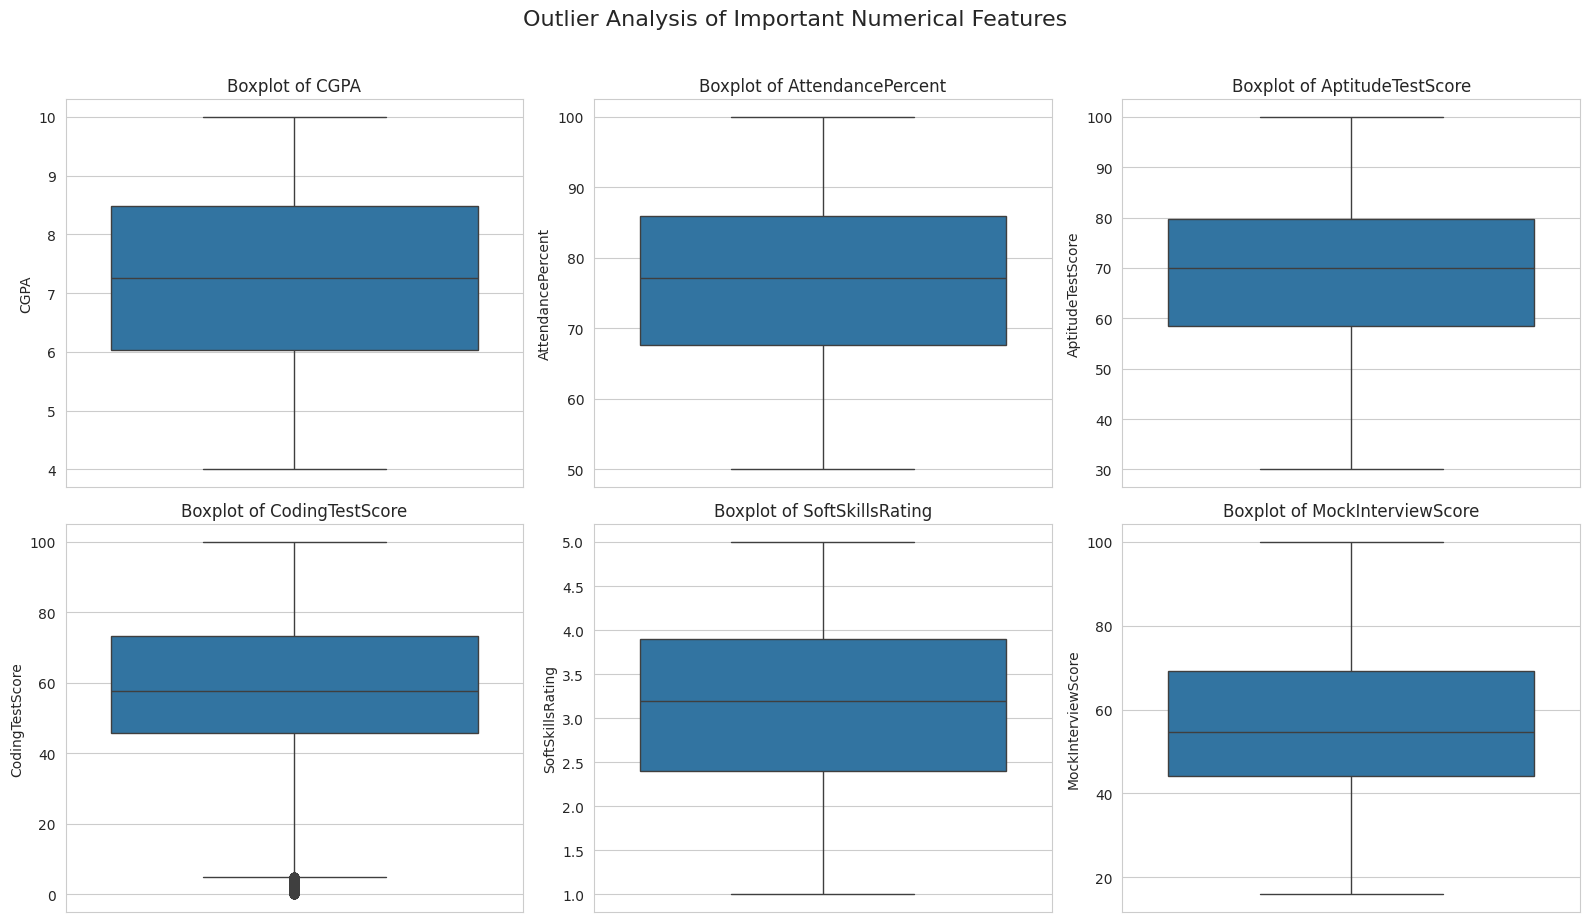

EDA_Report_Cleaned.pdf created successfully with 5 pages!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ============================================================
# PLACEMENT DATASET - CLEAN AND NON-REDUNDANT EDA
# ============================================================

# 1. Upload the dataset
from google.colab import files

uploaded = files.upload()


# 2. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.backends.backend_pdf import PdfPages


# 3. Load the dataset
# Do not change this filename

CSV_PATH = next(iter(uploaded))


df = pd.read_csv(CSV_PATH)


# 4. Remove accidental spaces from column names
df.columns = df.columns.str.strip()


# 5. Select only useful input columns and the target
INPUT_COLUMNS = [
    "Stream",
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular"
]

TARGET_COLUMN = "PlacementStatus"


# 6. Create the required DataFrame
data = df[INPUT_COLUMNS + [TARGET_COLUMN]].copy()


# 7. Ensure PlacementStatus is numeric
# In this dataset:
# 0 = Not Placed
# 1 = Placed

if data[TARGET_COLUMN].dtype == "object":

    data[TARGET_COLUMN] = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "placed": 1,
            "not placed": 0,
            "yes": 1,
            "no": 0,
            "1": 1,
            "0": 0
        })
    )

else:

    data[TARGET_COLUMN] = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )


# 8. Set chart appearance
sns.set_style("whitegrid")


# 9. Columns used for distribution and boxplot graphs
CONTINUOUS_COLUMNS = [
    "CGPA",
    "AttendancePercent",
    "AptitudeTestScore",
    "CodingTestScore",
    "SoftSkillsRating",
    "MockInterviewScore"
]


# 10. Numerical columns used for correlation
CORRELATION_COLUMNS = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular",
    "PlacementStatus"
]


# ============================================================
# CREATE THE PDF REPORT
# ============================================================

PDF_NAME = "EDA_Report_Cleaned.pdf"


with PdfPages(PDF_NAME) as pdf:

    # --------------------------------------------------------
    # PAGE 1: Missing Values Heatmap
    # --------------------------------------------------------

    fig1, ax1 = plt.subplots(figsize=(13, 6))

    sns.heatmap(
        data.isnull(),
        cbar=False,
        cmap="viridis",
        yticklabels=False,
        ax=ax1
    )

    ax1.set_title(
        "Missingness Heatmap - Selected Placement Features",
        fontsize=15
    )

    ax1.set_xlabel("Selected Columns")
    ax1.set_ylabel("Student Records")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    pdf.savefig(fig1, bbox_inches="tight")
    plt.show()


    # --------------------------------------------------------
    # PAGE 2: Distribution Graphs
    # --------------------------------------------------------

    fig2, axes2 = plt.subplots(
        2,
        3,
        figsize=(16, 9)
    )

    for index, column in enumerate(CONTINUOUS_COLUMNS):

        row, position = divmod(index, 3)

        sns.histplot(
            data=data,
            x=column,
            bins=30,
            kde=True,
            ax=axes2[row, position]
        )

        axes2[row, position].set_title(
            f"Distribution of {column}"
        )

        axes2[row, position].set_ylabel("Number of Students")

    fig2.suptitle(
        "Distribution of Important Numerical Features",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()

    pdf.savefig(fig2, bbox_inches="tight")
    plt.show()


    # --------------------------------------------------------
    # PAGE 3: Placement Rate by Stream
    # --------------------------------------------------------

    placement_rate = (
        data.groupby("Stream")[TARGET_COLUMN]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .reset_index()
    )

    placement_rate.columns = [
        "Stream",
        "Placement Rate (%)"
    ]

    fig3, ax3 = plt.subplots(figsize=(11, 6))

    sns.barplot(
        data=placement_rate,
        x="Stream",
        y="Placement Rate (%)",
        hue="Stream",
        palette="crest",
        legend=False,
        ax=ax3
    )

    ax3.set_title(
        "Placement Rate (%) by Stream",
        fontsize=15
    )

    ax3.set_xlabel("Stream")
    ax3.set_ylabel("Placement Rate (%)")

    ax3.set_ylim(
        0,
        min(
            100,
            placement_rate["Placement Rate (%)"].max() + 10
        )
    )

    plt.xticks(rotation=30, ha="right")

    # Display percentage above every bar
    for container in ax3.containers:

        ax3.bar_label(
            container,
            fmt="%.2f%%",
            padding=3
        )

    plt.tight_layout()

    pdf.savefig(fig3, bbox_inches="tight")
    plt.show()


    # --------------------------------------------------------
    # PAGE 4: Correlation Heatmap
    # --------------------------------------------------------

    correlation_data = data[CORRELATION_COLUMNS]

    correlation_matrix = correlation_data.corr(
        numeric_only=True
    )

    fig4, ax4 = plt.subplots(figsize=(13, 10))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5,
        ax=ax4
    )

    ax4.set_title(
        "Correlation Heatmap - Selected Numerical Features",
        fontsize=15
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    pdf.savefig(fig4, bbox_inches="tight")
    plt.show()


    # --------------------------------------------------------
    # PAGE 5: Boxplots
    # --------------------------------------------------------

    fig5, axes5 = plt.subplots(
        2,
        3,
        figsize=(16, 9)
    )

    for index, column in enumerate(CONTINUOUS_COLUMNS):

        row, position = divmod(index, 3)

        sns.boxplot(
            data=data,
            y=column,
            ax=axes5[row, position]
        )

        axes5[row, position].set_title(
            f"Boxplot of {column}"
        )

        axes5[row, position].set_xlabel("")

    fig5.suptitle(
        "Outlier Analysis of Important Numerical Features",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()

    pdf.savefig(fig5, bbox_inches="tight")
    plt.show()


print(f"{PDF_NAME} created successfully with 5 pages!")


# ============================================================
# DOWNLOAD THE PDF
# ============================================================

files.download(PDF_NAME)